# CSE422 Lab Project
## Hotel Booking Cancellation Prediction Using Machine Learning

---

| Field | Details |
|-------|---------|
| **Course** | CSE422 — Machine Learning |
| **Semester** | Summer 2026 |
| **University** | BRAC University |
| **Group** | 11 |
| **Member 1** | Afnan Jahan Prithila — 21201675 |
| **Member 2** | B.M. Muktadir Wafi — 22301737 |
| **Dataset** | Hotel Booking Demand (`11.csv`) |



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc,
    precision_score, recall_score, f1_score
)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

---
<a id='section1'></a>
# 1. Introduction

Hotel booking cancellations lead to severe revenue loss, unoccupied rooms, and inaccurate demand forecasts. This project leverages Machine Learning to predict whether a customer will cancel their hotel reservation.

- **Target Variable:** `is_canceled` (0 = Not Canceled / Kept, 1 = Canceled)
- **Problem Type:** Binary Classification

---
<a id='section2'></a>
# 2. Dataset Description

In [ ]:
df = pd.read_csv('11.csv')
print(f'Dataset Dimensions: {df.shape[0]:,} rows × {df.shape[1]} columns')
df.head()

Dataset Dimensions: 119,390 rows × 32 columns


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [ ]:
# Inspect column data types and non-null value counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [ ]:
# Separate quantitative (numerical) and qualitative (categorical) columns
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print(f'Numerical features ({len(numerical_cols)}):', numerical_cols)
print(f'\nCategorical features ({len(categorical_cols)}):', categorical_cols)

Numerical features (20): ['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']

Categorical features (12): ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']


Class 0 (Not Canceled): 75,166 (62.96%)
Class 1 (Canceled):     44,224 (37.04%)


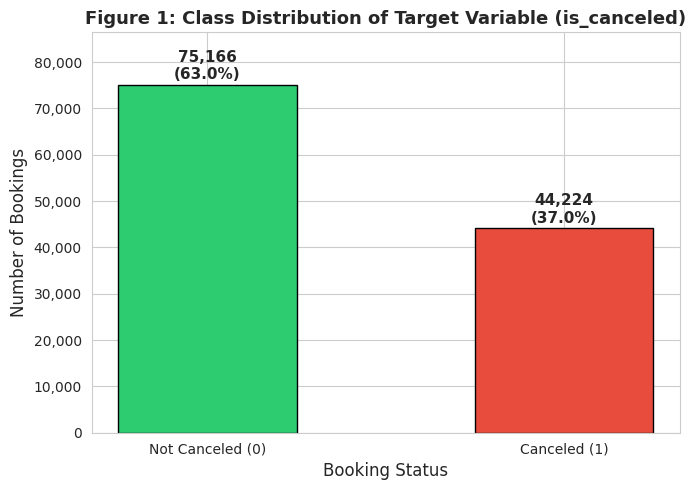

In [ ]:
# Calculate frequency and percentage distribution of the target variable (is_canceled)
class_counts = df['is_canceled'].value_counts()
class_percentages = df['is_canceled'].value_counts(normalize=True) * 100

print(f"Class 0 (Not Canceled): {class_counts[0]:,} ({class_percentages[0]:.2f}%)")
print(f"Class 1 (Canceled):     {class_counts[1]:,} ({class_percentages[1]:.2f}%)")

# Figure 1: Plot Target Class Balance Bar Chart
fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(
    ['Not Canceled (0)', 'Canceled (1)'],
    class_counts.values,
    color=['#2ecc71', '#e74c3c'],
    edgecolor='black',
    width=0.5
)

# Annotate bar tops with exact count and percentage
for bar, count, pct in zip(bars, class_counts.values, class_percentages.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 500,
        f'{count:,}\n({pct:.1f}%)',
        ha='center', va='bottom', fontsize=11, fontweight='bold'
    )

ax.set_title('Figure 1: Class Distribution of Target Variable (is_canceled)', fontsize=13, fontweight='bold')
ax.set_xlabel('Booking Status', fontsize=12)
ax.set_ylabel('Number of Bookings', fontsize=12)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.set_ylim(0, max(class_counts.values) * 1.15)
plt.tight_layout()
plt.savefig('class_distribution.png', bbox_inches='tight')
plt.show()

---
<a id='section3'></a>
# 3. Data Analysis (EDA)

In [ ]:
# Descriptive statistics (mean, std, min, quartiles, max) for numerical features
df[numerical_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.37,0.48,0.00,0.00,0.00,1.0,1.0
lead_time,119390.0,104.01,106.86,0.00,18.00,69.00,160.0,737.0
arrival_date_year,119390.0,2016.16,0.71,2015.00,2016.00,2016.00,2017.0,2017.0
arrival_date_week_number,119390.0,27.17,13.61,1.00,16.00,28.00,38.0,53.0
arrival_date_day_of_month,119390.0,15.80,8.78,1.00,8.00,16.00,23.0,31.0
stays_in_weekend_nights,119390.0,0.93,1.00,0.00,0.00,1.00,2.0,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.00,1.00,2.00,3.0,50.0
adults,119390.0,1.86,0.58,0.00,2.00,2.00,2.0,55.0
children,119386.0,0.10,0.40,0.00,0.00,0.00,0.0,10.0
babies,119390.0,0.01,0.10,0.00,0.00,0.00,0.0,10.0


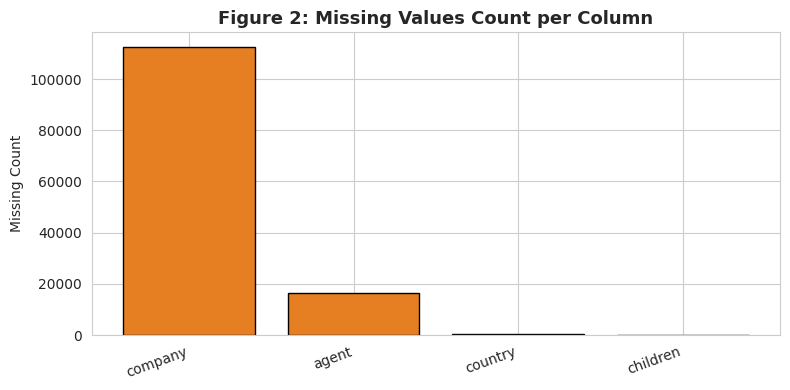

In [ ]:
# Identify columns containing null/missing values
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

# Figure 2: Plot Missing Values Bar Chart
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(missing.index, missing.values, color='#e67e22', edgecolor='black')
ax.set_title('Figure 2: Missing Values Count per Column', fontsize=13, fontweight='bold')
ax.set_ylabel('Missing Count')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig('missing_values.png', bbox_inches='tight')
plt.show()

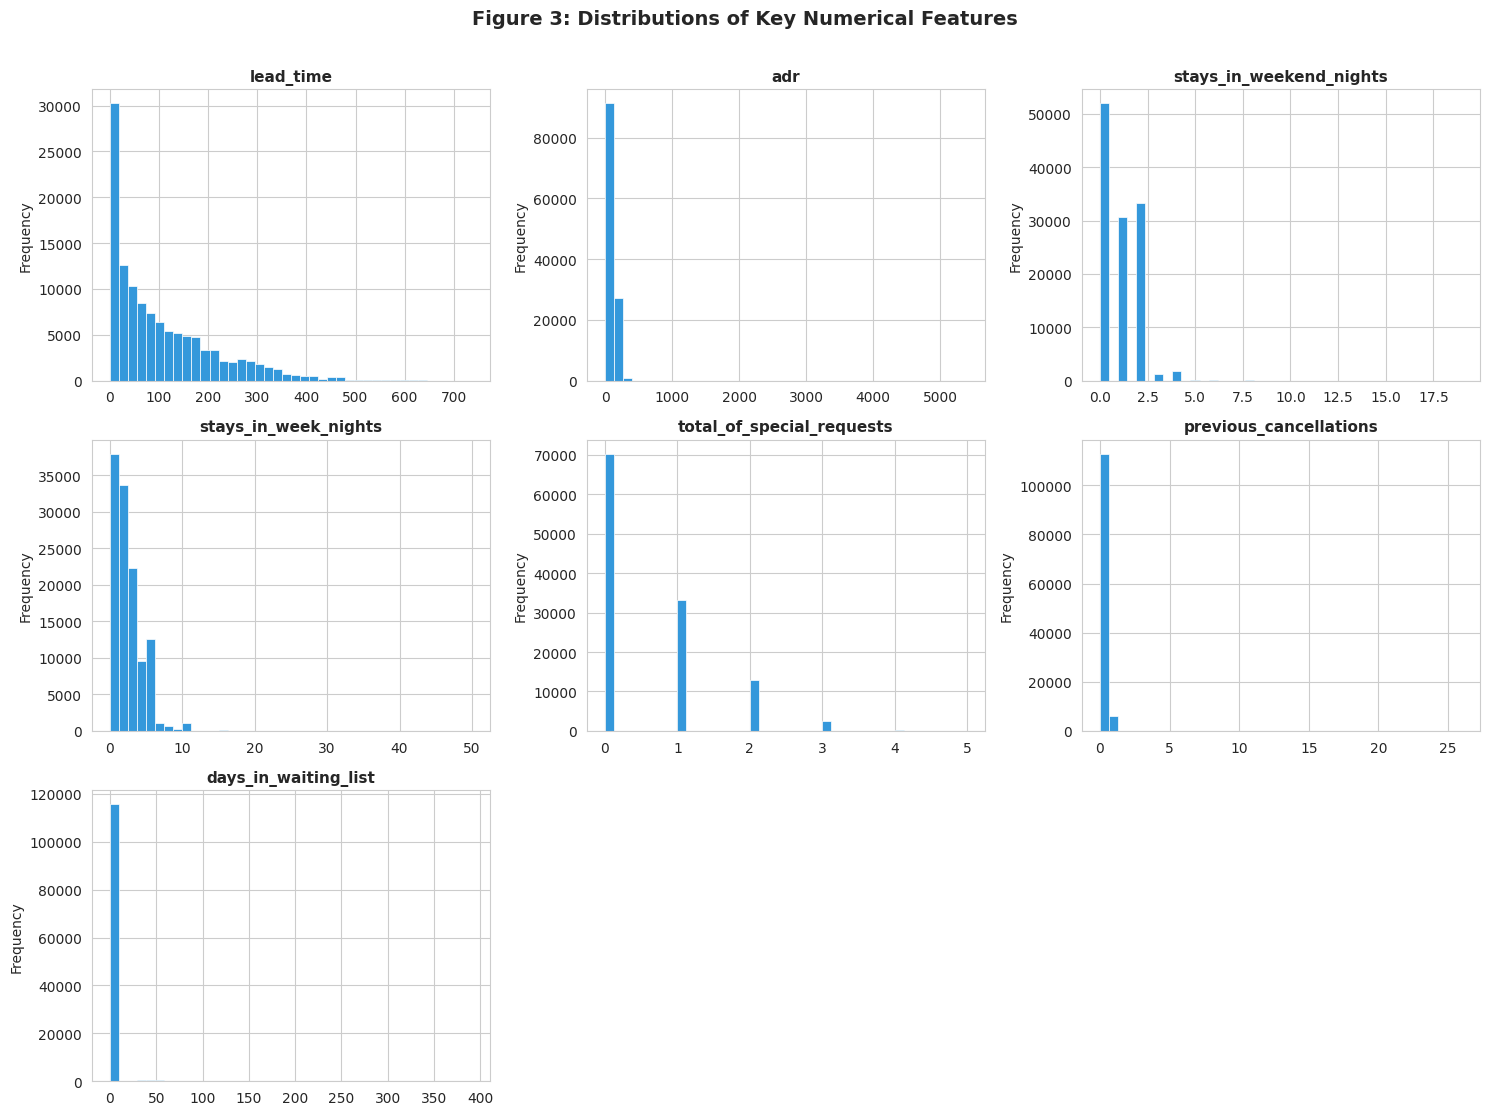

In [ ]:
# Select key numerical features to inspect distribution shape
key_num_cols = ['lead_time', 'adr', 'stays_in_weekend_nights',
                'stays_in_week_nights', 'total_of_special_requests',
                'previous_cancellations', 'days_in_waiting_list']

# Figure 3: Histograms of Key Numerical Features
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()

for i, col in enumerate(key_num_cols):
    axes[i].hist(df[col].dropna(), bins=40, color='#3498db', edgecolor='white', linewidth=0.5)
    axes[i].set_title(col, fontsize=11, fontweight='bold')
    axes[i].set_ylabel('Frequency')

# Hide unused subplot slots in 3x3 grid
for j in range(len(key_num_cols), len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Figure 3: Distributions of Key Numerical Features', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('histograms.png', bbox_inches='tight')
plt.show()

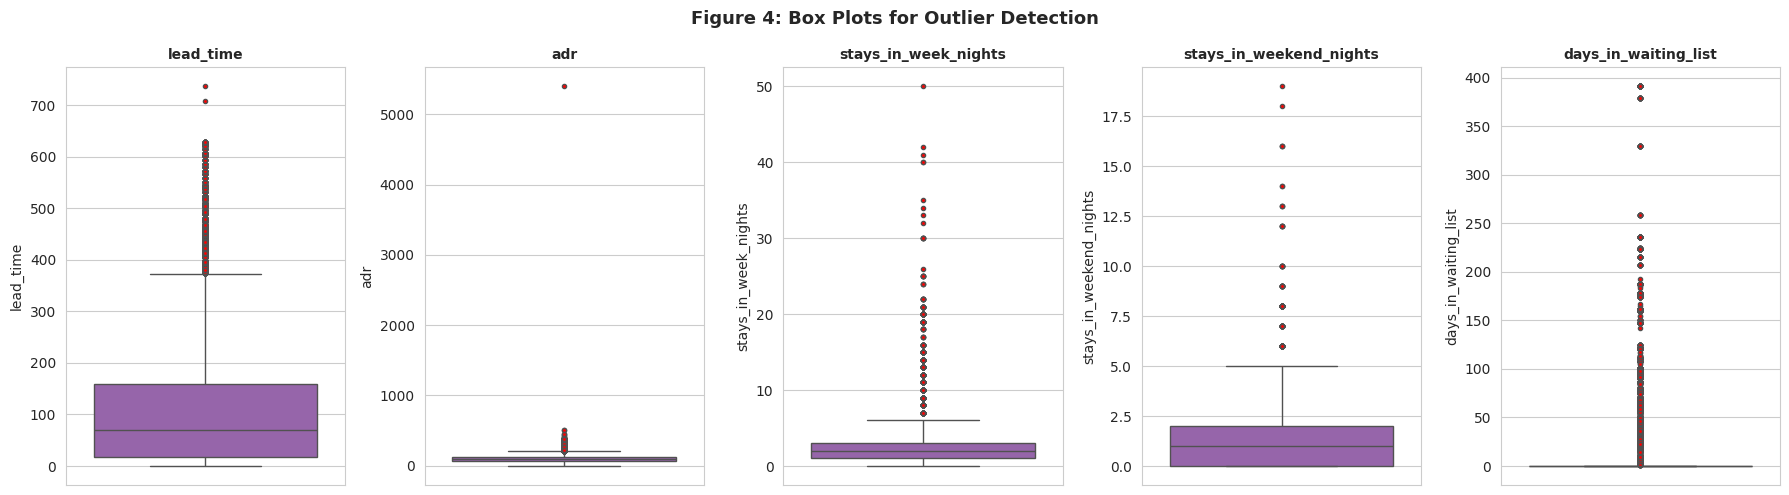

In [ ]:
# Figure 4: Box Plots for Outlier Detection across key numerical features
box_cols = ['lead_time', 'adr', 'stays_in_week_nights',
            'stays_in_weekend_nights', 'days_in_waiting_list']

fig, axes = plt.subplots(1, len(box_cols), figsize=(18, 5))
for ax, col in zip(axes, box_cols):
    sns.boxplot(y=df[col], ax=ax, color='#9b59b6',
                flierprops=dict(marker='o', markerfacecolor='red', markersize=3))
    ax.set_title(col, fontsize=10, fontweight='bold')

fig.suptitle('Figure 4: Box Plots for Outlier Detection', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('boxplots.png', bbox_inches='tight')
plt.show()

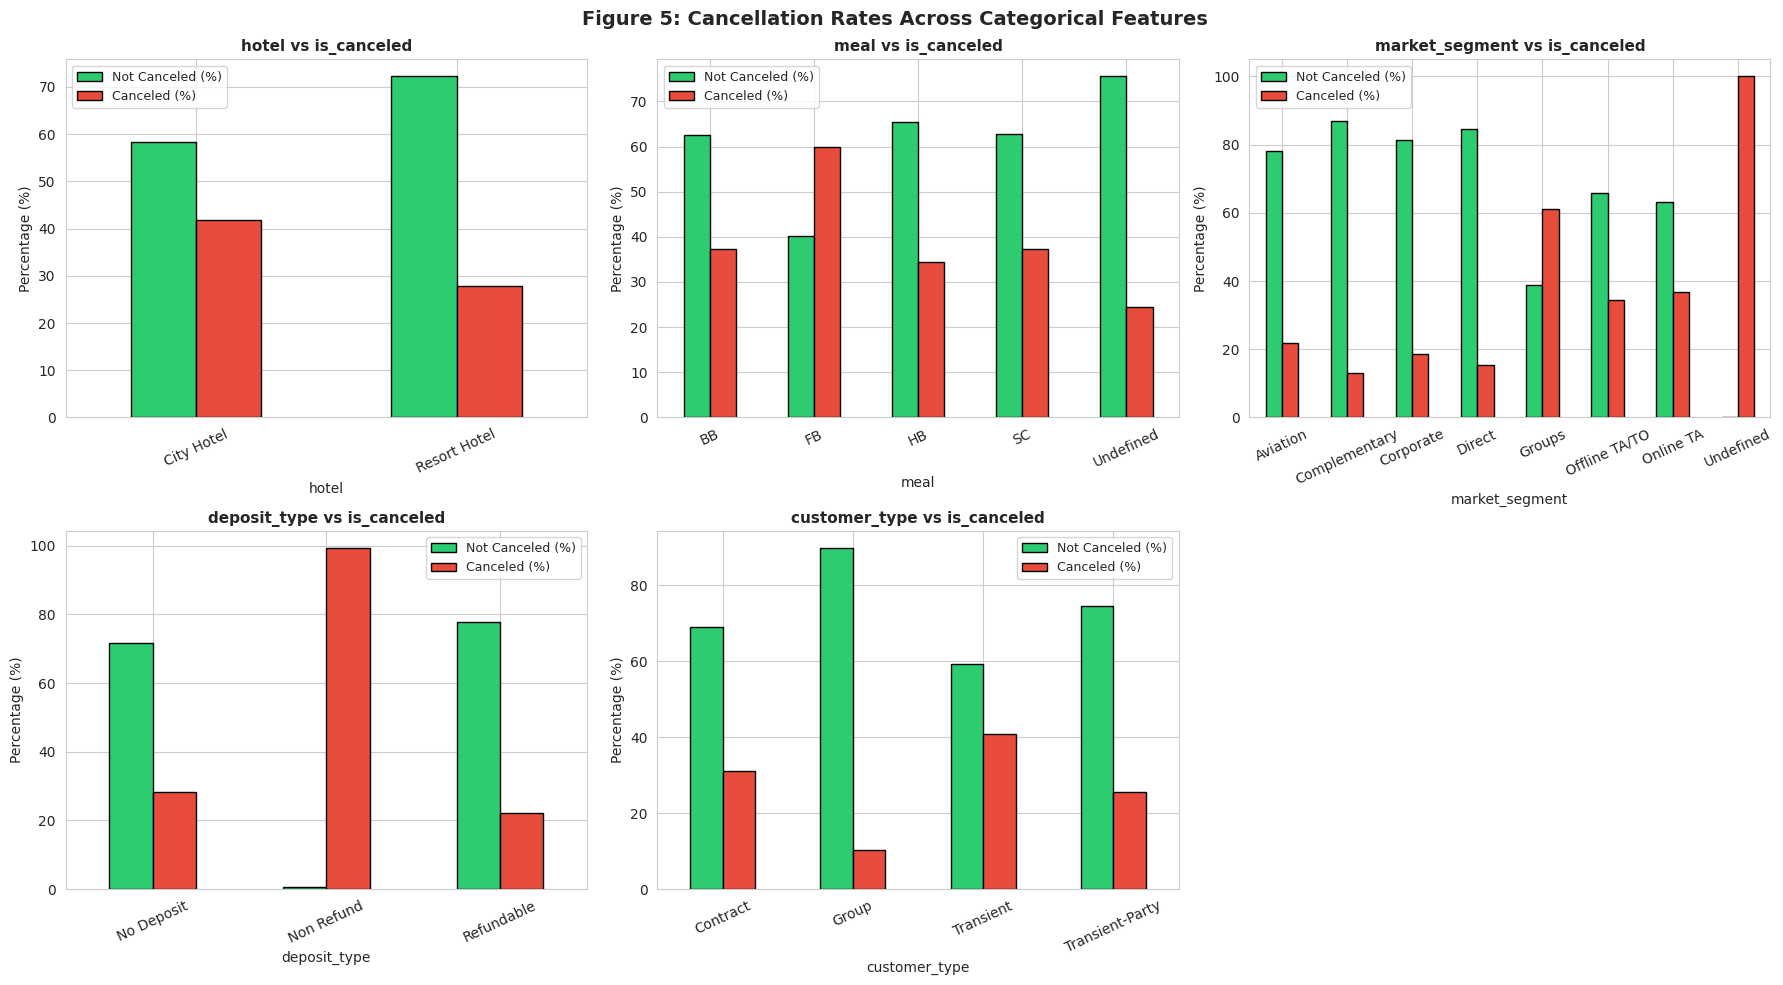

In [ ]:
# Figure 5: Categorical Crosstab Analysis vs is_canceled
key_cat_cols = ['hotel', 'meal', 'market_segment', 'deposit_type', 'customer_type']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(key_cat_cols):
    # Normalized crosstab to show percentage cancellation per category
    ct = pd.crosstab(df[col], df['is_canceled'], normalize='index') * 100
    ct.columns = ['Not Canceled (%)', 'Canceled (%)']
    ct.plot(kind='bar', ax=axes[i], color=['#2ecc71', '#e74c3c'], edgecolor='black', rot=25)
    axes[i].set_title(f'{col} vs is_canceled', fontsize=11, fontweight='bold')
    axes[i].set_ylabel('Percentage (%)')
    axes[i].legend(fontsize=9)

axes[5].set_visible(False)
fig.suptitle('Figure 5: Cancellation Rates Across Categorical Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('categorical_analysis.png', bbox_inches='tight')
plt.show()

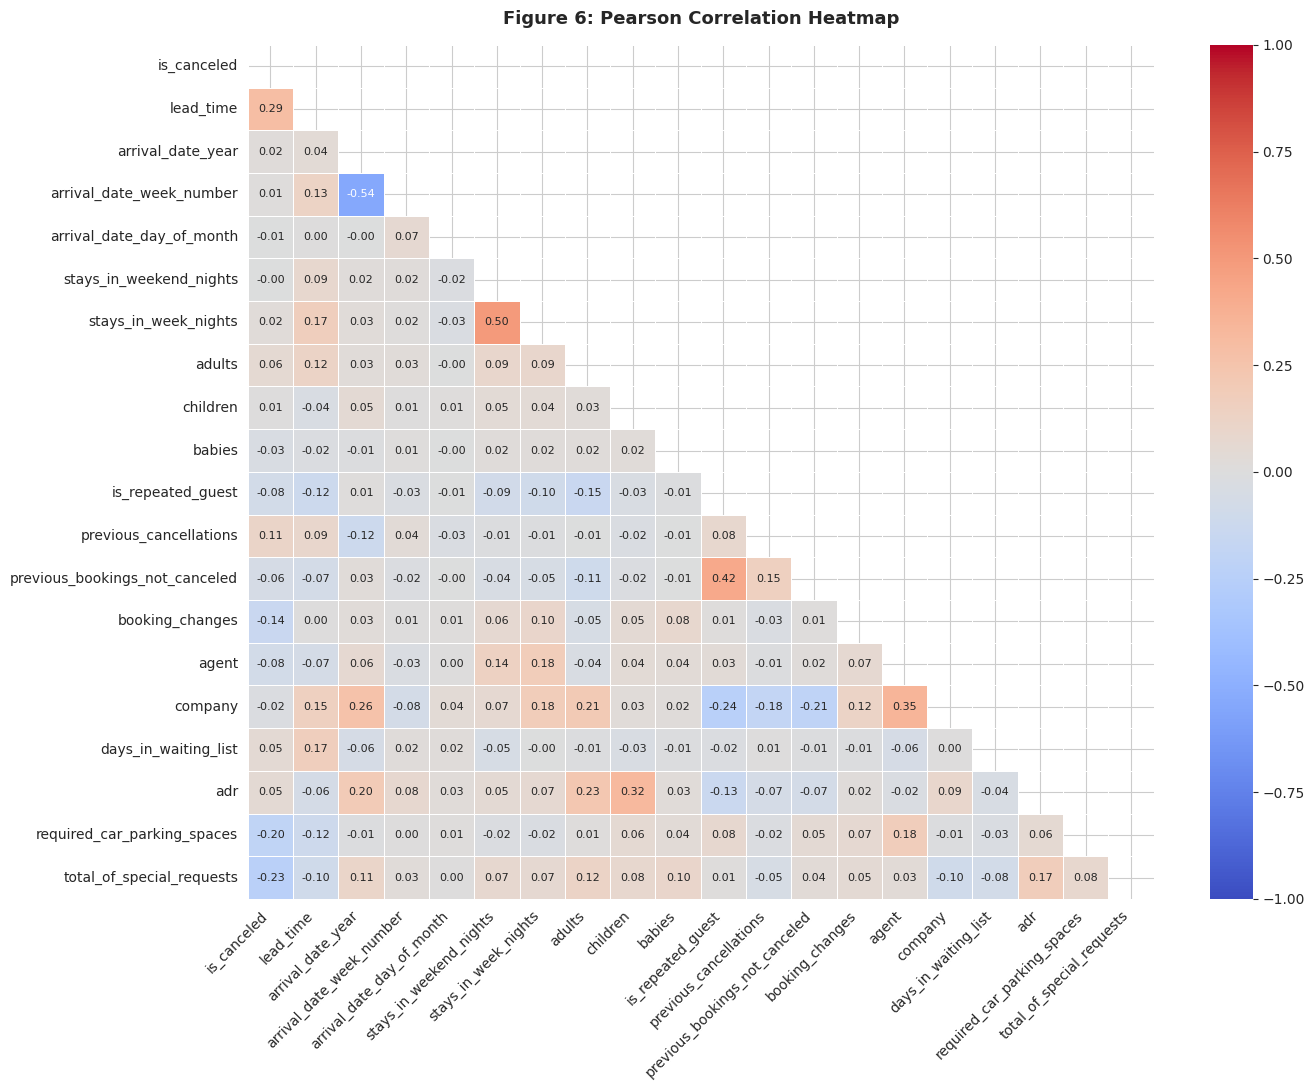

In [ ]:
# Figure 6: Pearson Correlation Heatmap across all numerical features
num_df = df[numerical_cols].copy()
pearson_corr = num_df.corr(method='pearson')

# Mask upper triangle to avoid redundant symmetric information
mask = np.triu(np.ones_like(pearson_corr, dtype=bool))

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(
    pearson_corr,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    ax=ax,
    annot_kws={'size': 8},
    vmin=-1, vmax=1
)
ax.set_title('Figure 6: Pearson Correlation Heatmap', fontsize=13, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', bbox_inches='tight')
plt.show()

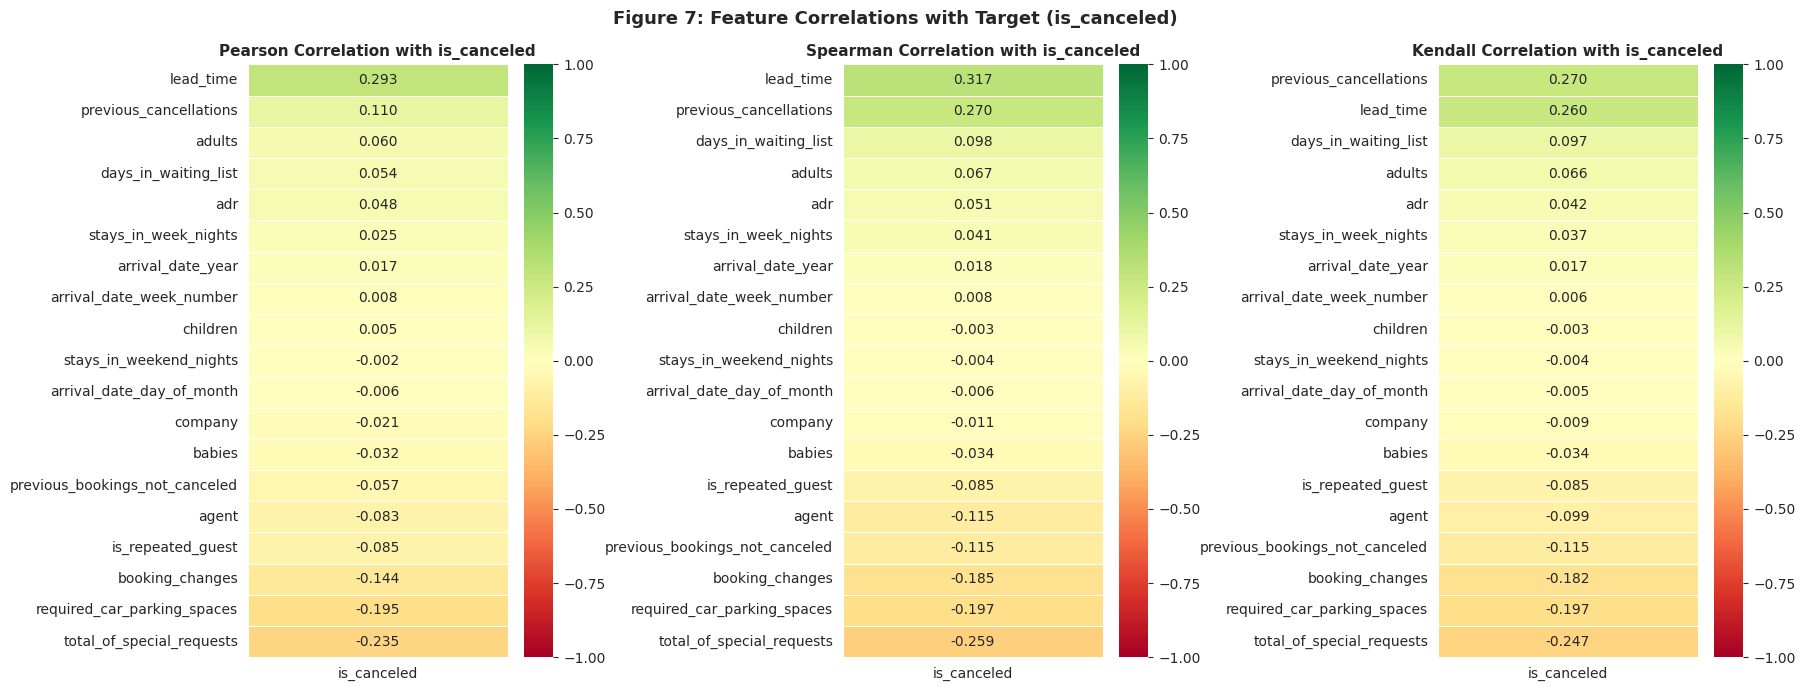

In [ ]:
# Figure 7: Compare Pearson, Spearman, and Kendall correlation with target variable
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
methods = ['pearson', 'spearman', 'kendall']

for ax, method in zip(axes, methods):
    # Compute correlation with target, drop target self-correlation, sort values
    corr_target = num_df.corr(method=method)[['is_canceled']].drop('is_canceled').sort_values('is_canceled', ascending=False)
    sns.heatmap(corr_target, annot=True, fmt='.3f', cmap='RdYlGn', vmin=-1, vmax=1, ax=ax, linewidths=0.5)
    ax.set_title(f'{method.capitalize()} Correlation with is_canceled', fontsize=11, fontweight='bold')

fig.suptitle('Figure 7: Feature Correlations with Target (is_canceled)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('target_correlation.png', bbox_inches='tight')
plt.show()

---
<a id='section4'></a>
# 4. Dataset Pre-processing

In [ ]:
# Create an independent working copy
data = df.copy()

# Step 1: Drop Data Leakage features (reservation_status directly reveals cancellation outcome)
data.drop(columns=['reservation_status', 'reservation_status_date'], inplace=True)

# Step 2: Drop high-cardinality nominal feature (country has 178 categories -> curse of dimensionality)
data.drop(columns=['country'], inplace=True)

# Step 3: Handle missing values (0 denotes no agent, no company, 0 children)
data['agent'].fillna(0, inplace=True)
data['company'].fillna(0, inplace=True)
data['children'].fillna(0, inplace=True)

# Step 4: Remove exact duplicate rows
data.drop_duplicates(inplace=True)

# Step 5: Encode nominal categorical features into numeric integers using LabelEncoder
categorical_features = data.select_dtypes(include='object').columns.tolist()
label_encoders = {}
for col in categorical_features:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col].astype(str))
    label_encoders[col] = le

# Step 6: Convert imputed identifier and count columns from float to integer
data['agent'] = data['agent'].astype(int)
data['company'] = data['company'].astype(int)
data['children'] = data['children'].astype(int)

# Step 7: Separate feature matrix (X) and target label vector (y)
X = data.drop(columns=['is_canceled'])
y = data['is_canceled']

print(f'Processed Feature Matrix Shape: {X.shape}')
print(f'Processed Target Vector Shape:  {y.shape}')

Processed Feature Matrix Shape: (85351, 28)
Processed Target Vector Shape:  (85351,)


---
<a id='section5'></a>
# 5. Dataset Splitting

In [ ]:
# Perform 80/20 Stratified Train-Test Split to preserve target class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

# Apply StandardScaler: Fit on training data only, transform both train and test to prevent leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'Training Samples: {X_train.shape[0]:,}')
print(f'Testing Samples:  {X_test.shape[0]:,}')

Training Samples: 68,280
Testing Samples:  17,071


---
<a id='section6'></a>
# 6. Model Training & Testing (Supervised)

In [ ]:
# Dictionary to store metrics and predictions for all models
results = {}

def evaluate_model(name, y_true, y_pred, y_prob):
    """Compute and store classification metrics (Accuracy, Precision, Recall, F1, AUC)."""
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc_score = auc(fpr, tpr)

    # Save metrics in dictionary for Section 7 comparison
    results[name] = {
        'accuracy': acc,
        'precision': prec,
        'recall': rec,
        'f1': f1,
        'auc': auc_score,
        'y_pred': y_pred,
        'y_prob': y_prob,
        'fpr': fpr,
        'tpr': tpr
    }

    print(f'=== {name} ===')
    print(f'Accuracy:  {acc:.4f}')
    print(f'Precision: {prec:.4f}')
    print(f'Recall:    {rec:.4f}')
    print(f'F1-Score:  {f1:.4f}')
    print(f'AUC:       {auc_score:.4f}\n')

### 6.1 K-Nearest Neighbors (KNN)

In [ ]:
# Model 1: K-Nearest Neighbors Classifier (trained on scaled features)
knn = KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2, n_jobs=-1)
knn.fit(X_train_scaled, y_train)

# Predict test set classes and probabilities
y_pred_knn = knn.predict(X_test_scaled)
y_prob_knn = knn.predict_proba(X_test_scaled)[:, 1]

# Evaluate KNN performance
evaluate_model('KNN', y_test, y_pred_knn, y_prob_knn)

=== KNN ===
Accuracy:  0.7737
Precision: 0.6087
Recall:    0.5203
F1-Score:  0.5611
AUC:       0.7841



### 6.2 Decision Tree

=== Decision Tree ===
Accuracy:  0.8039
Precision: 0.7305
Recall:    0.4668
F1-Score:  0.5696
AUC:       0.8305



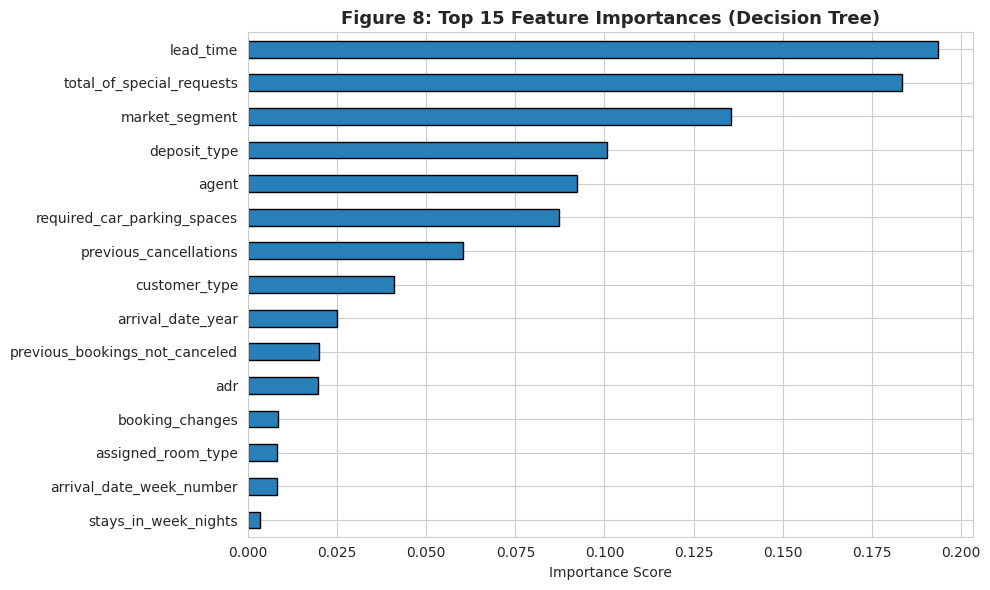

In [ ]:
# Model 2: Decision Tree Classifier (max_depth=10 to prevent overfitting)
dt = DecisionTreeClassifier(criterion='gini', max_depth=10, min_samples_split=20, random_state=RANDOM_STATE)
dt.fit(X_train, y_train)

# Predict test set classes and probabilities
y_pred_dt = dt.predict(X_test)
y_prob_dt = dt.predict_proba(X_test)[:, 1]

# Evaluate Decision Tree performance
evaluate_model('Decision Tree', y_test, y_pred_dt, y_prob_dt)

# Figure 8: Plot Top 15 Feature Importances computed by the Decision Tree
feat_imp = pd.Series(dt.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(10, 6))
feat_imp.plot(kind='barh', ax=ax, color='#2980b9', edgecolor='black')
ax.set_title('Figure 8: Top 15 Feature Importances (Decision Tree)', fontsize=13, fontweight='bold')
ax.set_xlabel('Importance Score')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('feature_importance_dt.png', bbox_inches='tight')
plt.show()

### 6.3 Logistic Regression

In [ ]:
# Model 3: Logistic Regression Classifier (trained on scaled features using L-BFGS solver)
lr = LogisticRegression(max_iter=1000, solver='lbfgs', random_state=RANDOM_STATE, n_jobs=-1)
lr.fit(X_train_scaled, y_train)

# Predict test set classes and probabilities
y_pred_lr = lr.predict(X_test_scaled)
y_prob_lr = lr.predict_proba(X_test_scaled)[:, 1]

# Evaluate Logistic Regression performance
evaluate_model('Logistic Regression', y_test, y_pred_lr, y_prob_lr)

=== Logistic Regression ===
Accuracy:  0.7752
Precision: 0.7000
Recall:    0.3345
F1-Score:  0.4527
AUC:       0.7971



### 6.4 Gaussian Naive Bayes

In [ ]:
# Model 4: Gaussian Naive Bayes Classifier
nb = GaussianNB()
nb.fit(X_train_scaled, y_train)

# Predict test set classes and probabilities
y_pred_nb = nb.predict(X_test_scaled)
y_prob_nb = nb.predict_proba(X_test_scaled)[:, 1]

# Evaluate Gaussian Naive Bayes performance
evaluate_model('Naive Bayes', y_test, y_pred_nb, y_prob_nb)

=== Naive Bayes ===
Accuracy:  0.4181
Precision: 0.3199
Recall:    0.9711
F1-Score:  0.4813
AUC:       0.7388



### 6.5 Neural Network (TensorFlow / Keras)

Epoch 1/50
121/121 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.7330 - loss: 0.5393 - val_accuracy: 0.7702 - val_loss: 0.4936
Epoch 2/50
121/121 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.7729 - loss: 0.4783 - val_accuracy: 0.7862 - val_loss: 0.4572
Epoch 3/50
121/121 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.7806 - loss: 0.4644 - val_accuracy: 0.7919 - val_loss: 0.4452
Epoch 4/50
121/121 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.7880 - loss: 0.4573 - val_accuracy: 0.7913 - val_loss: 0.4380
Epoch 5/50
121/121 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.7928 - loss: 0.4492 - val_accuracy: 0.7958 - val_loss: 0.4335
Epoch 6/50
121/121 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7924 - loss: 0.4445 - val_accuracy: 0.7973 - val_loss: 0.4286
Epoch 7/50
121/121 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7960 - loss: 0.4400 - val_accuracy: 0.8007 - val_loss: 0.4264
Epoch 8/50
121/121 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7965 - loss: 0.4364 - val_accura

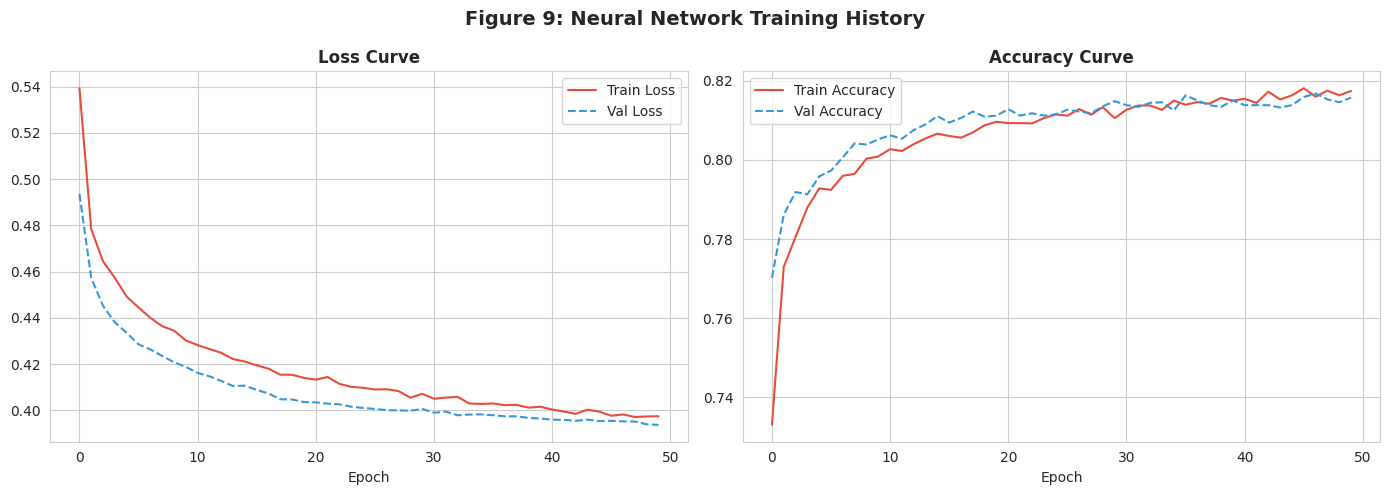

=== Neural Network ===
Accuracy:  0.8161
Precision: 0.7297
Recall:    0.5376
F1-Score:  0.6191
AUC:       0.8602



In [ ]:
# Model 5: Deep Neural Network Architecture with BatchNormalization and Dropout
nn_model = Sequential([
    Dense(128, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    BatchNormalization(),
    Dropout(0.3),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

# Compile model using Adam optimizer and binary cross-entropy loss
nn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Early stopping callback to prevent overfitting and save best weights
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)

# Train Neural Network
nn_history = nn_model.fit(
    X_train_scaled, y_train,
    epochs=50,
    batch_size=512,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

# Figure 9: Plot Training and Validation Loss / Accuracy Learning Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(nn_history.history['loss'], label='Train Loss', color='#e74c3c')
ax1.plot(nn_history.history['val_loss'], label='Val Loss', color='#3498db', linestyle='--')
ax1.set_title('Loss Curve', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.legend()

ax2.plot(nn_history.history['accuracy'], label='Train Accuracy', color='#e74c3c')
ax2.plot(nn_history.history['val_accuracy'], label='Val Accuracy', color='#3498db', linestyle='--')
ax2.set_title('Accuracy Curve', fontsize=12, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.legend()

fig.suptitle('Figure 9: Neural Network Training History', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('nn_learning_curves.png', bbox_inches='tight')
plt.show()

# Predict test set probabilities and apply 0.5 threshold for binary class
y_prob_nn = nn_model.predict(X_test_scaled, verbose=0).flatten()
y_pred_nn = (y_prob_nn >= 0.5).astype(int)

# Evaluate Neural Network performance
evaluate_model('Neural Network', y_test, y_pred_nn, y_prob_nn)

---
<a id='section7'></a>
# 7. Model Selection & Comparison Analysis

Model Performance Summary:


,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Model,,,,,
Neural Network,0.8161,0.7297,0.5376,0.6191,0.8602
Decision Tree,0.8039,0.7305,0.4668,0.5696,0.8305
KNN,0.7737,0.6087,0.5203,0.5611,0.7841
Naive Bayes,0.4181,0.3199,0.9711,0.4813,0.7388
Logistic Regression,0.7752,0.7000,0.3345,0.4527,0.7971


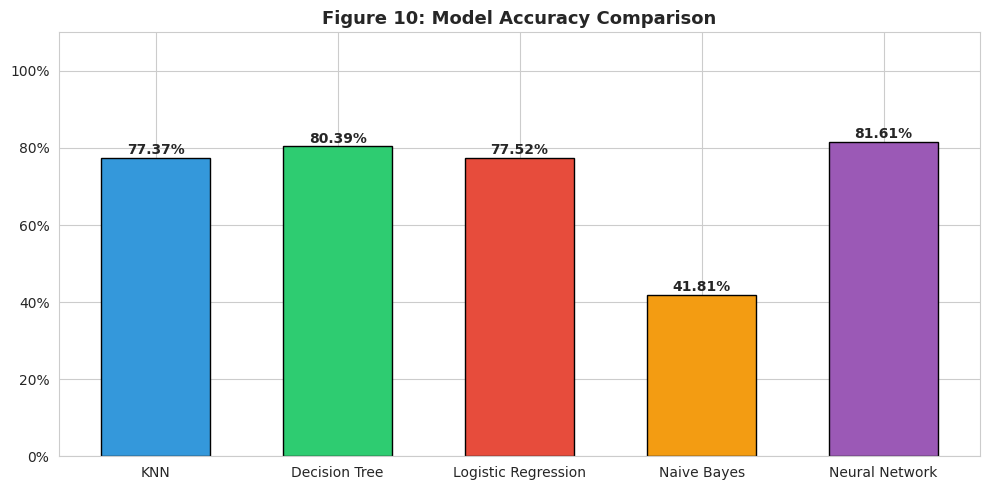

In [ ]:
# Aggregate metrics across all 5 models into a structured comparison table
comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Accuracy': [r['accuracy'] for r in results.values()],
    'Precision': [r['precision'] for r in results.values()],
    'Recall': [r['recall'] for r in results.values()],
    'F1-Score': [r['f1'] for r in results.values()],
    'AUC-ROC': [r['auc'] for r in results.values()]
}).set_index('Model').round(4).sort_values('F1-Score', ascending=False)

print('Model Performance Summary:')
display(comparison_df)

# Figure 10: Bar Chart Comparing Prediction Accuracy across all 5 models
model_names = list(results.keys())
accuracies = [results[m]['accuracy'] for m in model_names]
colors = ['#3498db', '#2ecc71', '#e74c3c', '#f39c12', '#9b59b6']

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(model_names, accuracies, color=colors, edgecolor='black', width=0.6)
for bar, acc in zip(bars, accuracies):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{acc*100:.2f}%', ha='center', fontweight='bold')
ax.set_title('Figure 10: Model Accuracy Comparison', fontsize=13, fontweight='bold')
ax.set_ylim(0, 1.1)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
plt.tight_layout()
plt.savefig('accuracy_comparison.png', bbox_inches='tight')
plt.show()

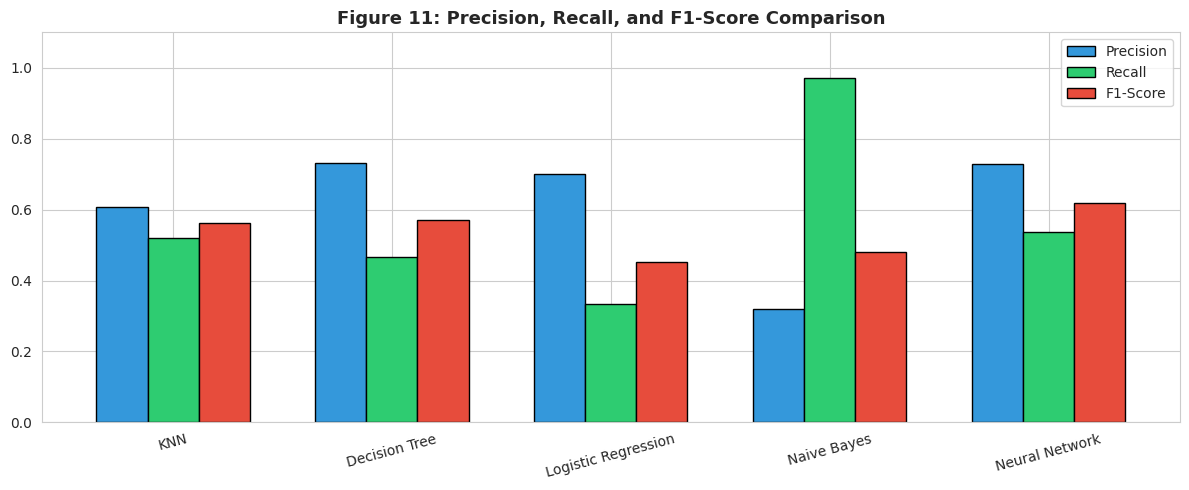

In [ ]:
# Figure 11: Grouped Bar Chart comparing Precision, Recall, and F1-Score
metrics_df = pd.DataFrame({
    'Precision': [results[m]['precision'] for m in model_names],
    'Recall': [results[m]['recall'] for m in model_names],
    'F1-Score': [results[m]['f1'] for m in model_names]
}, index=model_names)

fig, ax = plt.subplots(figsize=(12, 5))
metrics_df.plot(kind='bar', ax=ax, color=['#3498db', '#2ecc71', '#e74c3c'], edgecolor='black', rot=15, width=0.7)
ax.set_title('Figure 11: Precision, Recall, and F1-Score Comparison', fontsize=13, fontweight='bold')
ax.set_ylim(0, 1.1)
plt.tight_layout()
plt.savefig('precision_recall_f1.png', bbox_inches='tight')
plt.show()

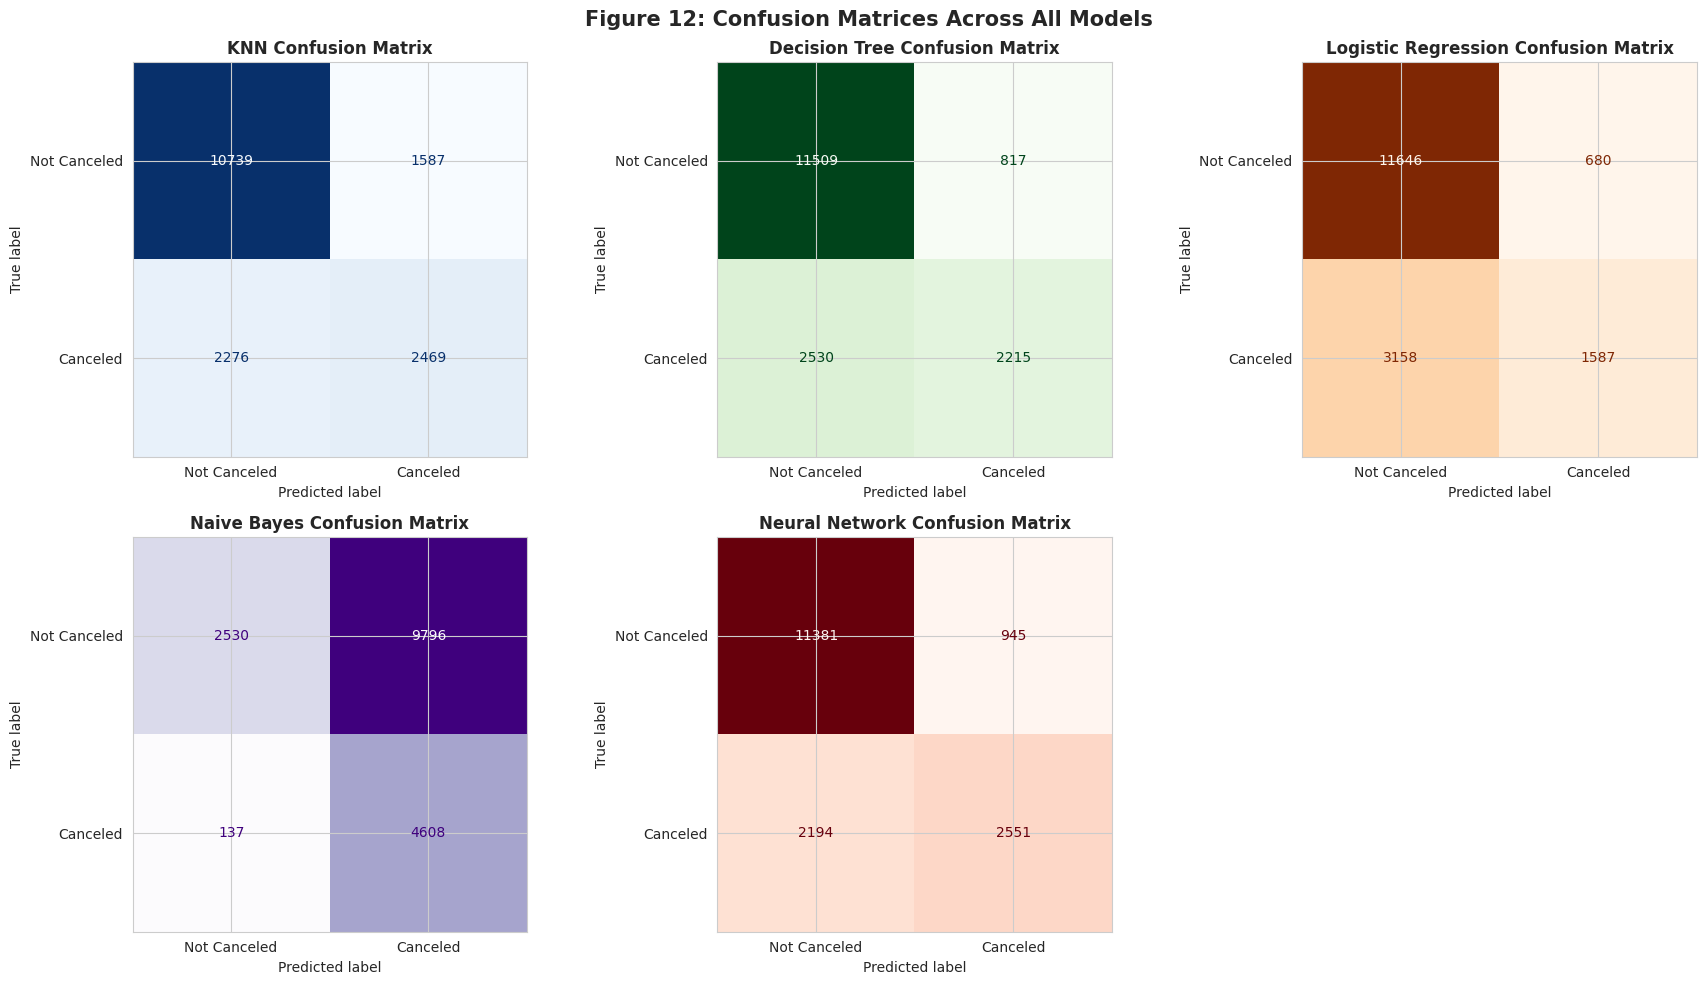

In [ ]:
# Figure 12: Grid of Confusion Matrices for all 5 Models
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
cmaps = ['Blues', 'Greens', 'Oranges', 'Purples', 'Reds']

for i, (m, c) in enumerate(zip(model_names, cmaps)):
    cm = confusion_matrix(y_test, results[m]['y_pred'])
    ConfusionMatrixDisplay(cm, display_labels=['Not Canceled', 'Canceled']).plot(ax=axes[i], cmap=c, colorbar=False)
    axes[i].set_title(f'{m} Confusion Matrix', fontweight='bold')

axes[5].set_visible(False)
fig.suptitle('Figure 12: Confusion Matrices Across All Models', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrices.png', bbox_inches='tight')
plt.show()

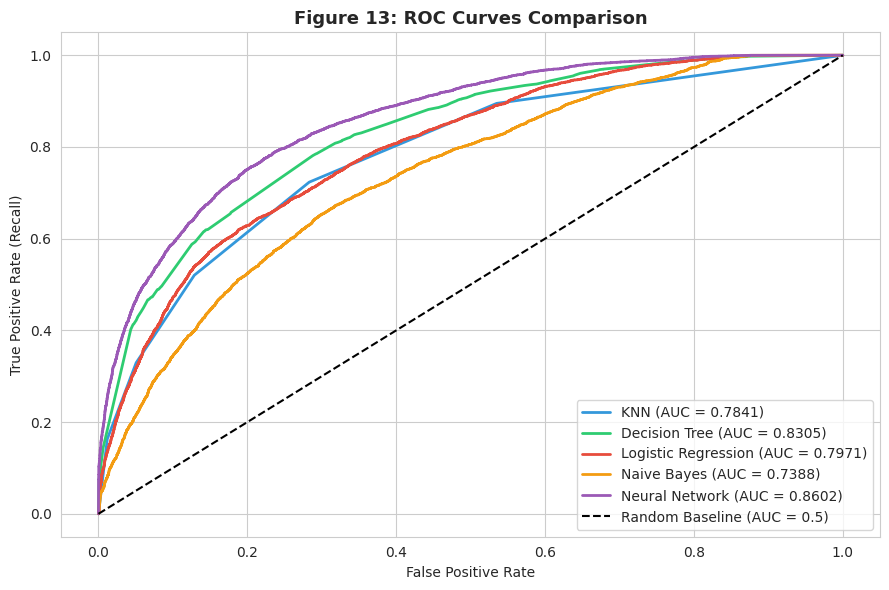

In [ ]:
# Figure 13: Receiver Operating Characteristic (ROC) Curves with AUC Score Comparison
fig, ax = plt.subplots(figsize=(9, 6))
for m, c in zip(model_names, colors):
    ax.plot(results[m]['fpr'], results[m]['tpr'], color=c, linewidth=2, label=f"{m} (AUC = {results[m]['auc']:.4f})")

# Plot random chance baseline (AUC = 0.5)
ax.plot([0, 1], [0, 1], 'k--', label='Random Baseline (AUC = 0.5)')
ax.set_title('Figure 13: ROC Curves Comparison', fontsize=13, fontweight='bold')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate (Recall)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('roc_curves.png', bbox_inches='tight')
plt.show()

---
<a id='section8'></a>
# 8. Unsupervised Learning (K-Means Clustering)

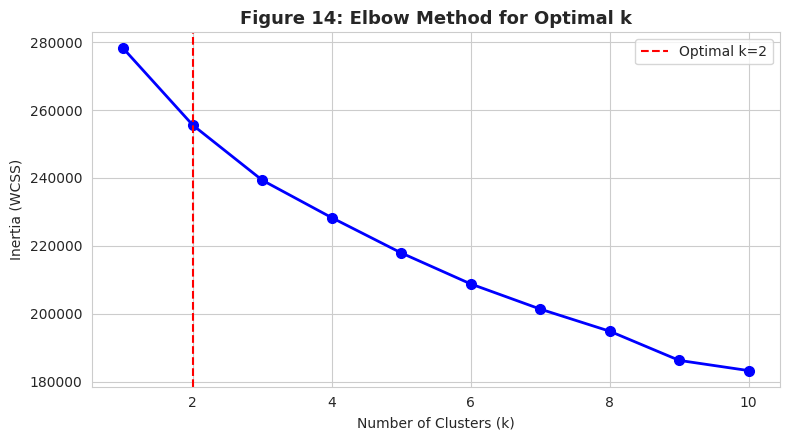

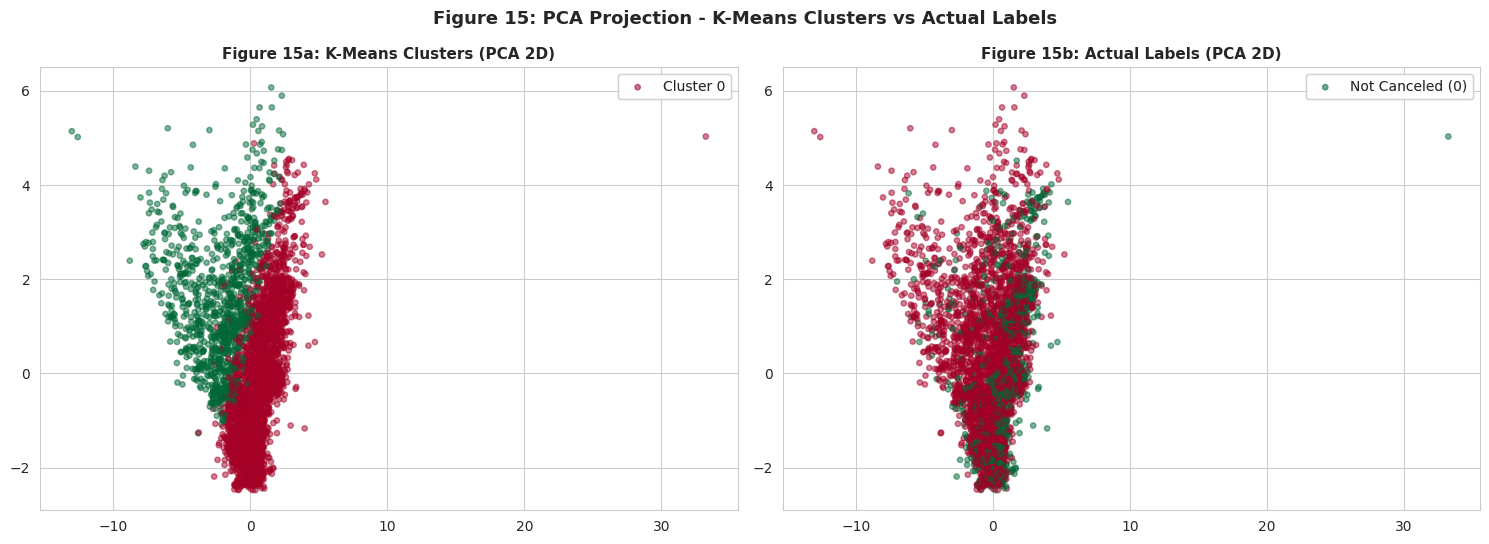

Cluster vs Actual Label Cross-Tabulation:
Actual Status      0      1
Cluster                    
0              36737  16936
1              12565   2042


In [ ]:
# Step 1: Remove target variable to create purely unsupervised feature set
X_unsup = X_train_scaled.copy()

# Step 2: Compute WCSS (Inertia) over k=1..10 using Elbow Method (subsample for efficiency)
np.random.seed(RANDOM_STATE)
sample_idx = np.random.choice(len(X_unsup), size=min(10000, len(X_unsup)), replace=False)
X_sample = X_unsup[sample_idx]

inertia_values = []
k_range = range(1, 11)
for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=5, random_state=RANDOM_STATE)
    km.fit(X_sample)
    inertia_values.append(km.inertia_)

# Figure 14: Plot Elbow Curve to identify optimal number of clusters
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(k_range, inertia_values, 'bo-', markersize=7, linewidth=2)
ax.axvline(x=2, color='red', linestyle='--', label='Optimal k=2')
ax.set_title('Figure 14: Elbow Method for Optimal k', fontsize=13, fontweight='bold')
ax.set_xlabel('Number of Clusters (k)')
ax.set_ylabel('Inertia (WCSS)')
ax.legend()
plt.tight_layout()
plt.savefig('elbow_method.png', bbox_inches='tight')
plt.show()

# Step 3: Train final K-Means model with optimal k=2 on full training features
kmeans = KMeans(n_clusters=2, init='k-means++', n_init=10, max_iter=300, random_state=RANDOM_STATE)
kmeans.fit(X_unsup)
cluster_labels = kmeans.labels_

# Step 4: Reduce features to 2D via PCA for 2D visual cluster analysis
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_unsup[:5000])
cluster_sample = cluster_labels[:5000]
actual_sample = y_train.values[:5000]

# Figure 15: PCA Projection comparing K-Means clusters vs Ground Truth labels
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))
s1 = ax1.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_sample, cmap='RdYlGn', alpha=0.5, s=15)
ax1.set_title('Figure 15a: K-Means Clusters (PCA 2D)', fontsize=11, fontweight='bold')
ax1.add_artist(ax1.legend(*s1.legend_elements(), labels=['Cluster 0', 'Cluster 1']))

s2 = ax2.scatter(X_pca[:, 0], X_pca[:, 1], c=actual_sample, cmap='RdYlGn', alpha=0.5, s=15)
ax2.set_title('Figure 15b: Actual Labels (PCA 2D)', fontsize=11, fontweight='bold')
ax2.add_artist(ax2.legend(*s2.legend_elements(), labels=['Not Canceled (0)', 'Canceled (1)']))

fig.suptitle('Figure 15: PCA Projection - K-Means Clusters vs Actual Labels', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('kmeans_clusters.png', bbox_inches='tight')
plt.show()

# Step 5: Cross-tabulate cluster assignments with actual cancellation labels
ct = pd.crosstab(cluster_labels, y_train.values, rownames=['Cluster'], colnames=['Actual Status'])
print('Cluster vs Actual Label Cross-Tabulation:')
print(ct)

---
<a id='section9'></a>
# 9. Conclusion

In [ ]:
# Determine top-performing models
best_f1_model = comparison_df.index[0]
best_auc_model = comparison_df.sort_values('AUC-ROC', ascending=False).index[0]

print('=' * 50)
print('FINAL PROJECT SUMMARY')
print('=' * 50)
print(f'Best Model by F1-Score: {best_f1_model} ({comparison_df.loc[best_f1_model, "F1-Score"]:.4f})')
print(f'Best Model by AUC-ROC:  {best_auc_model} ({comparison_df.loc[best_auc_model, "AUC-ROC"]:.4f})')
print('=' * 50)
print('\nAll Models Summary:')
print(comparison_df)

FINAL PROJECT SUMMARY
Best Model by F1-Score: Neural Network (0.6191)
Best Model by AUC-ROC:  Neural Network (0.8602)

All Models Summary:
                     Accuracy  Precision  Recall  F1-Score  AUC-ROC
Model                                                              
Neural Network         0.8161     0.7297  0.5376    0.6191   0.8602
Decision Tree          0.8039     0.7305  0.4668    0.5696   0.8305
KNN                    0.7737     0.6087  0.5203    0.5611   0.7841
Naive Bayes            0.4181     0.3199  0.9711    0.4813   0.7388
Logistic Regression    0.7752     0.7000  0.3345    0.4527   0.7971
